In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import warnings; warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

train = pd.read_csv("/kaggle/input/competitions/flight-price-prediction/train.csv")
test  = pd.read_csv("/kaggle/input/competitions/flight-price-prediction/test.csv")
TARGET   = "price"
CAT_COLS = ["airline","source_city","departure_time","stops",
            "arrival_time","destination_city","flight_class"]
NUM_COLS = ["duration","days_left"]

In [4]:
print(train.dtypes)
print(train[NUM_COLS + [TARGET]].describe().T)
print(train[CAT_COLS + ["flight"]].describe().T)

id                    int64
airline              object
flight               object
source_city          object
departure_time       object
stops                object
arrival_time         object
destination_city     object
flight_class         object
duration            float64
days_left             int64
price                 int64
dtype: object
             count        mean         std   min     25%     50%    75%      max
duration   18076.0    2.746853    2.947519  0.87    1.47    1.63    2.0    28.65
days_left  18076.0   20.520912   12.094984  1.00   10.00   20.00   31.0    44.00
price      18076.0  280.264550  221.965133  0.00  157.00  234.00  336.0  8996.00
                  count unique              top   freq
airline           18076      7  Alaska_Airlines   4554
source_city       18076      5      Los Angeles   4561
departure_time    18076      6          Morning   5144
stops             18076      3             zero  13559
arrival_time      18076      6        Afternoon   4

In [5]:
print("Missing (train):", train.isna().sum().sum(), "| Missing (test):", test.isna().sum().sum())
print("Duplicate rows (ignoring id):", train.drop(columns="id").duplicated().sum())
print("Duplicate ids:", train["id"].duplicated().sum())
print("Price <= 0:", (train[TARGET] <= 0).sum())
print("Duration <= 0:", (train["duration"] <= 0).sum(), "| days_left < 0:", (train["days_left"] < 0).sum())

Missing (train): 0 | Missing (test): 0
Duplicate rows (ignoring id): 6
Duplicate ids: 0
Price <= 0: 25
Duration <= 0: 0 | days_left < 0: 0


airline            train=    7 test=    6 unseen in test=0
source_city        train=    5 test=    5 unseen in test=0
departure_time     train=    6 test=    6 unseen in test=0
stops              train=    3 test=    3 unseen in test=0
arrival_time       train=    6 test=    6 unseen in test=0
destination_city   train=    5 test=    5 unseen in test=0
flight_class       train=    2 test=    2 unseen in test=0
flight             train= 1123 test=  790 unseen in test=33
duration train (0.87, 28.65) test (0.87, 25.9)
days_left train (1, 44) test (1, 44)


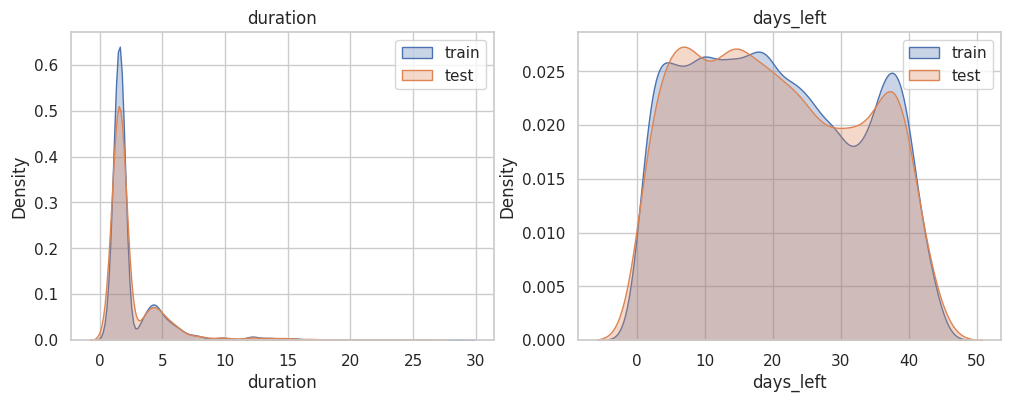

In [6]:
for c in CAT_COLS + ["flight"]:
    unseen = set(test[c]) - set(train[c])
    print(f"{c:18s} train={train[c].nunique():5d} test={test[c].nunique():5d} unseen in test={len(unseen)}")
for c in NUM_COLS:
    print(c, "train", (train[c].min(), train[c].max()), "test", (test[c].min(), test[c].max()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, c in zip(axes, NUM_COLS):
    sns.kdeplot(train[c], label="train", fill=True, alpha=.3, ax=ax)
    sns.kdeplot(test[c],  label="test",  fill=True, alpha=.3, ax=ax)
    ax.set_title(c); ax.legend()
plt.show()

skew=7.07  kurtosis=170.25  log1p skew=-0.74
0.01      59.00
0.05      69.00
0.25     157.00
0.50     234.00
0.75     336.00
0.95     656.25
0.99    1016.00
Name: price, dtype: float64


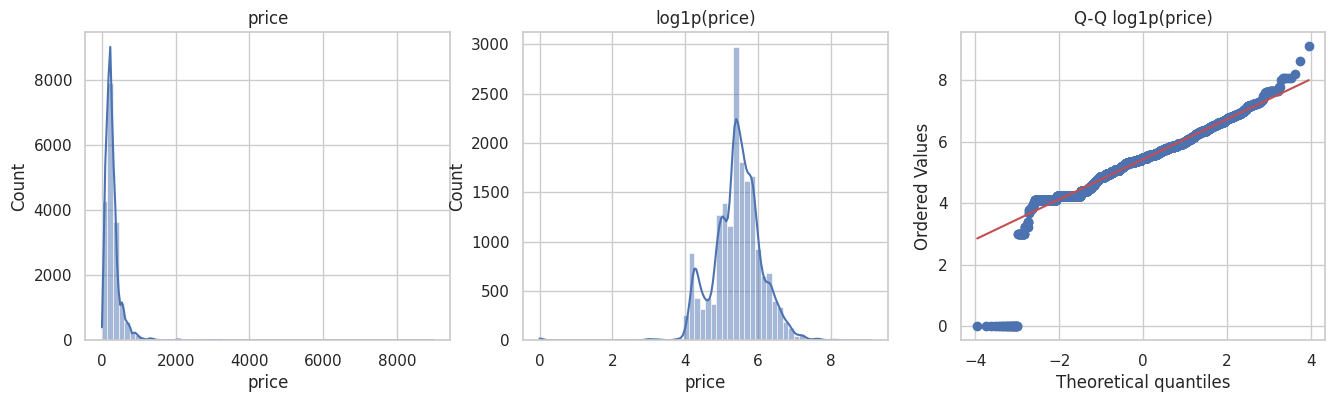

In [7]:
y = train[TARGET]
print(f"skew={y.skew():.2f}  kurtosis={y.kurt():.2f}  log1p skew={np.log1p(y).skew():.2f}")
print(y.quantile([.01,.05,.25,.5,.75,.95,.99]))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(y, bins=60, kde=True, ax=axes[0]);            axes[0].set_title("price")
sns.histplot(np.log1p(y), bins=60, kde=True, ax=axes[1]);  axes[1].set_title("log1p(price)")
stats.probplot(np.log1p(y), plot=axes[2]);                 axes[2].set_title("Q-Q log1p(price)")
plt.show()

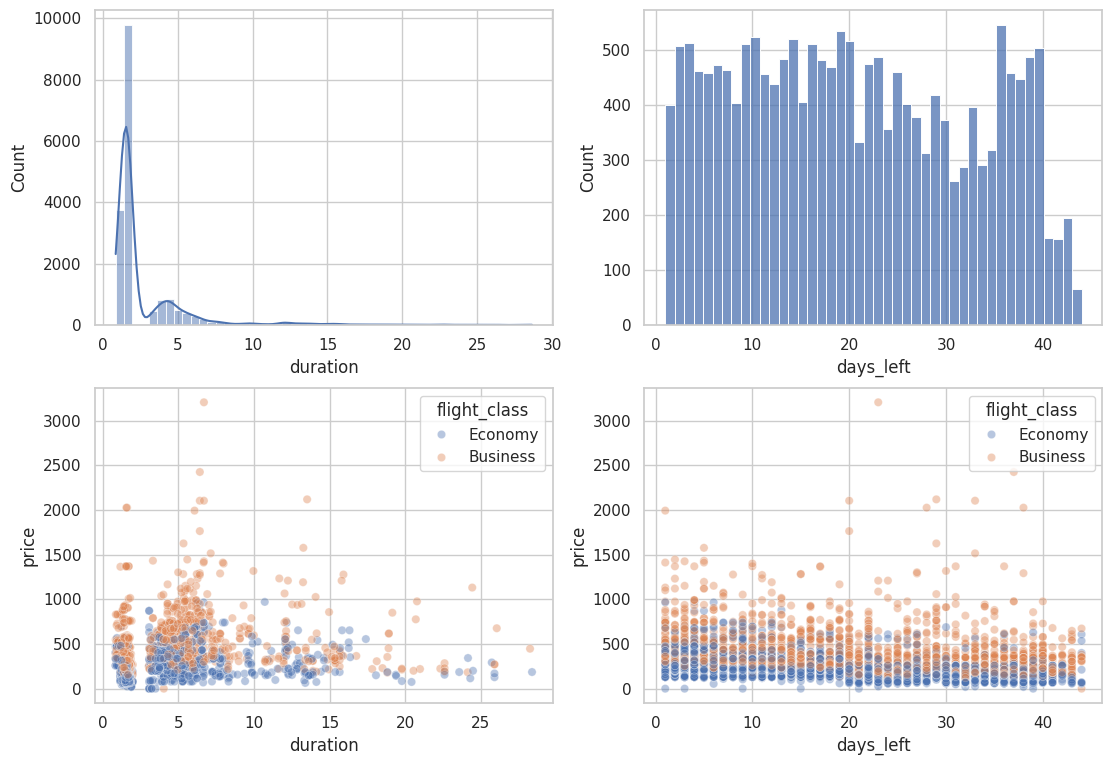

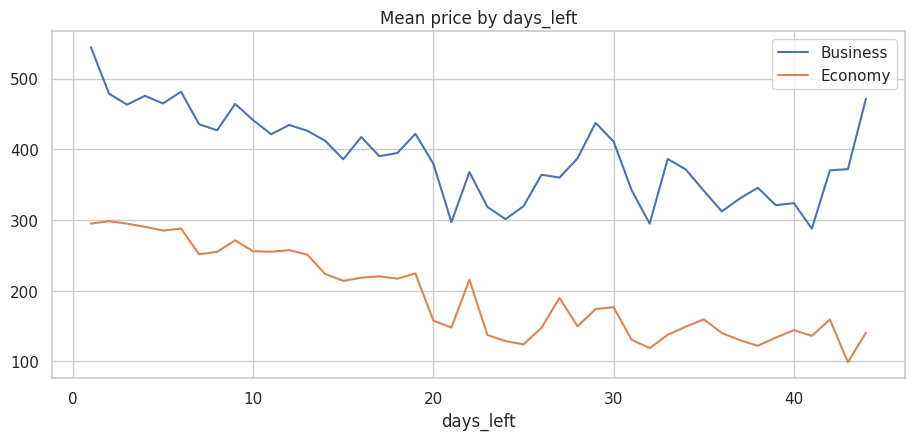

duration     0.281357
days_left   -0.229164
price        1.000000
Name: price, dtype: float64
duration     0.174478
days_left   -0.365492
price        1.000000
Name: price, dtype: float64


In [8]:
s = train.sample(5000, random_state=0)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.histplot(train["duration"], bins=50, kde=True, ax=axes[0,0])
sns.histplot(train["days_left"], bins=44, ax=axes[0,1])
sns.scatterplot(data=s, x="duration", y=TARGET, hue="flight_class", alpha=.4, ax=axes[1,0])
sns.scatterplot(data=s, x="days_left", y=TARGET, hue="flight_class", alpha=.4, ax=axes[1,1])
plt.show()

fig, ax = plt.subplots(figsize=(11, 4.5))
for cls, g in train.groupby("flight_class"):
    g.groupby("days_left")[TARGET].mean().plot(ax=ax, label=cls)
ax.set_title("Mean price by days_left"); ax.legend(); plt.show()

print(train[NUM_COLS + [TARGET]].corr()[TARGET])
print(train[NUM_COLS + [TARGET]].corr(method="spearman")[TARGET])

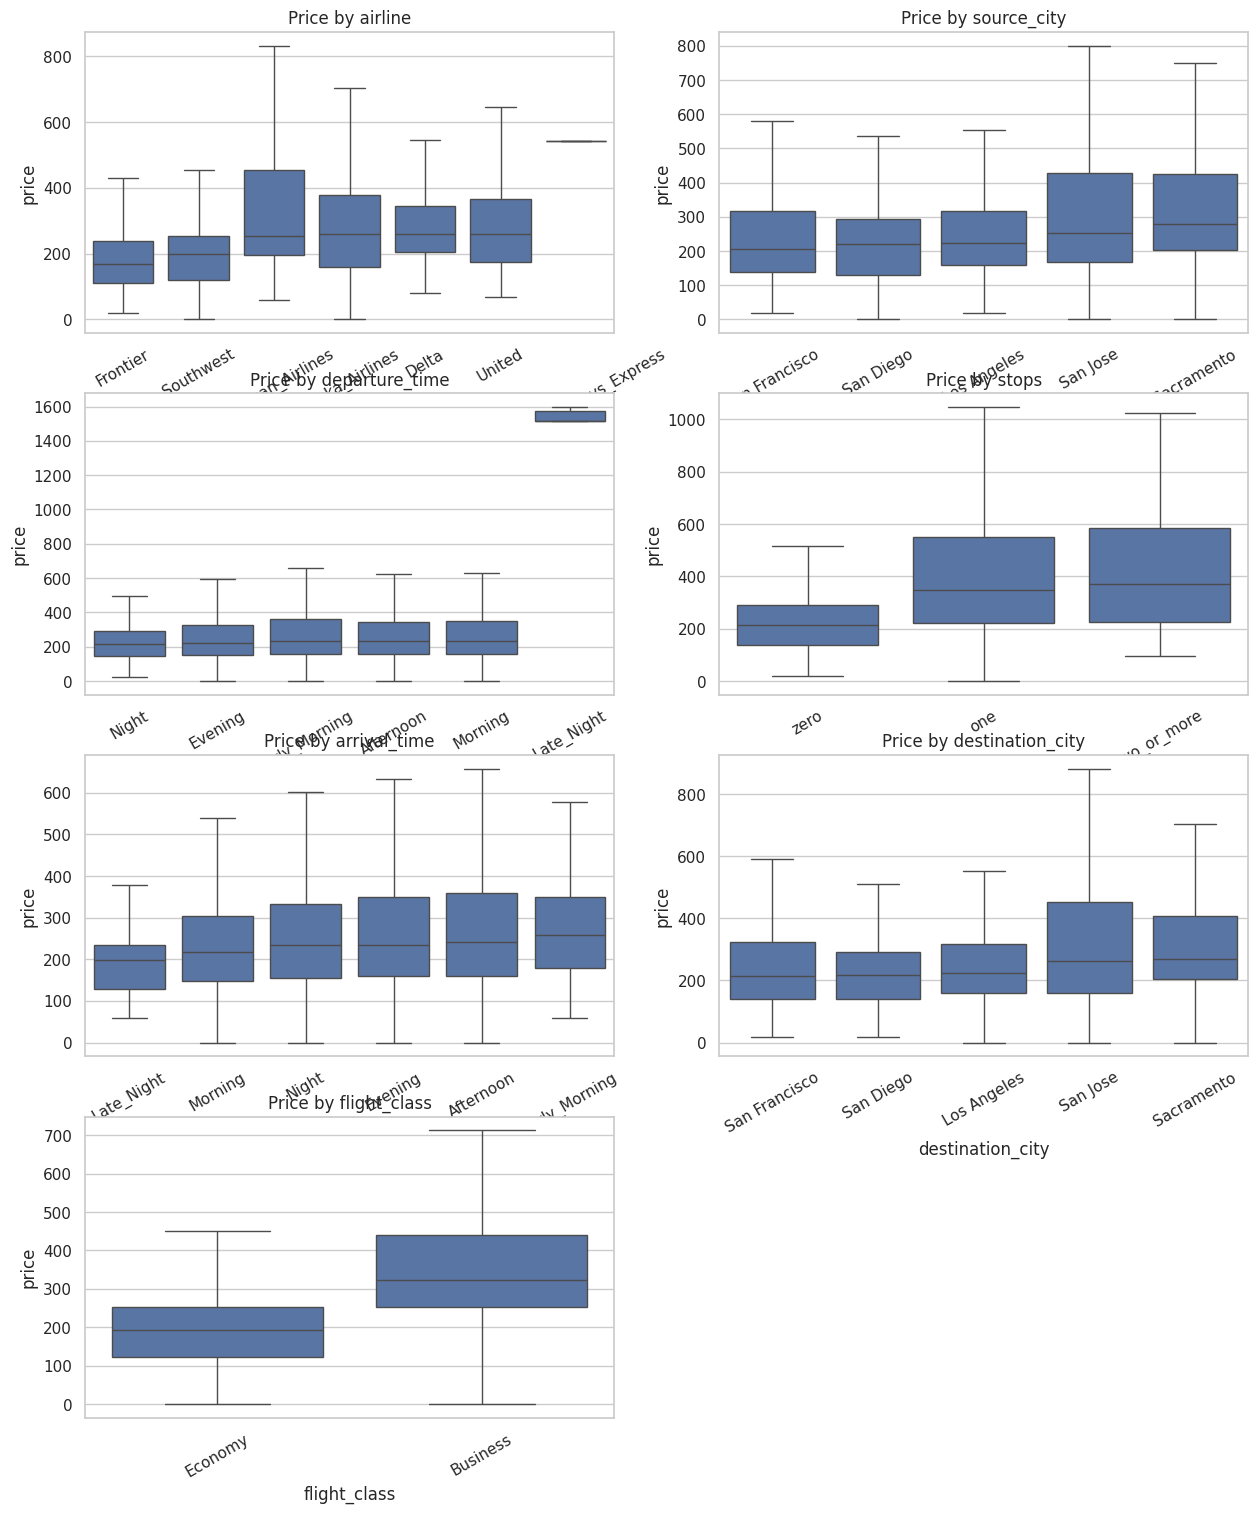

                          count   mean  median    std
airline                                              
Frontier                    799  178.6   168.0   95.2
Southwest                  3895  197.8   199.0  105.1
Delta                      2972  286.5   259.0  151.0
Alaska_Airlines            4554  302.6   259.0  226.7
United                     4058  319.0   259.0  302.6
American_Airlines          1797  349.4   253.0  253.3
Southern_Airways_Express      1  543.0   543.0    NaN 

               count   mean  median    std
source_city                               
San Diego       3691  234.1   220.0  176.0
San Francisco   4086  250.3   207.0  172.8
Los Angeles     4561  258.3   224.0  208.8
San Jose        2217  341.2   254.0  275.9
Sacramento      3521  353.5   279.0  264.3 

                count    mean  median     std
departure_time                               
Night            1777   236.4   217.0   200.3
Evening          4436   260.8   224.0   168.6
Afternoon        3893   2

In [9]:
fig, axes = plt.subplots(4, 2, figsize=(15, 18))
for ax, c in zip(axes.ravel(), CAT_COLS):
    order = train.groupby(c)[TARGET].median().sort_values().index
    sns.boxplot(data=train, x=c, y=TARGET, order=order, showfliers=False, ax=ax)
    ax.set_title(f"Price by {c}"); ax.tick_params(axis="x", rotation=30)
axes.ravel()[-1].axis("off"); plt.show()

for c in CAT_COLS:
    print(train.groupby(c)[TARGET].agg(["count","mean","median","std"]).sort_values("mean").round(1), "\n")

In [10]:
train["flight_code"] = train["flight"].str.extract(r"^([A-Za-z0-9]+)\s")[0]
train["flight_num"]  = pd.to_numeric(train["flight"].str.extract(r"(\d+)$")[0])
print(train["flight"].nunique(), train["flight_code"].nunique())
print(pd.crosstab(train["airline"], train["flight_code"]))
print("single-occurrence flights:", (train["flight"].value_counts() == 1).sum())
print("corr(flight_num, price):", train[["flight_num", TARGET]].corr().iloc[0,1].round(3))

1123 7
flight_code               9X    AA    AS    DL   F9    UA    WN
airline                                                        
Alaska_Airlines            0     0  4554     0    0     0     0
American_Airlines          0  1797     0     0    0     0     0
Delta                      0     0     0  2972    0     0     0
Frontier                   0     0     0     0  799     0     0
Southern_Airways_Express   1     0     0     0    0     0     0
Southwest                  0     0     0     0    0     0  3895
United                     0     0     0     0    0  4058     0
single-occurrence flights: 180
corr(flight_num, price): -0.049


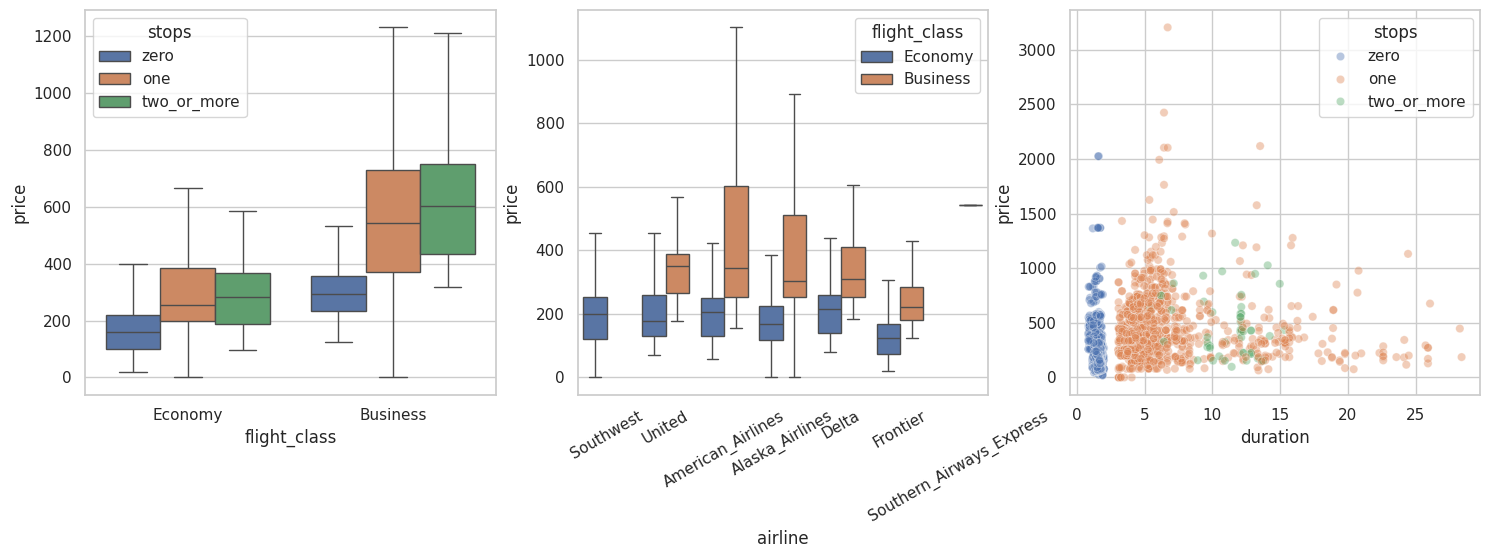

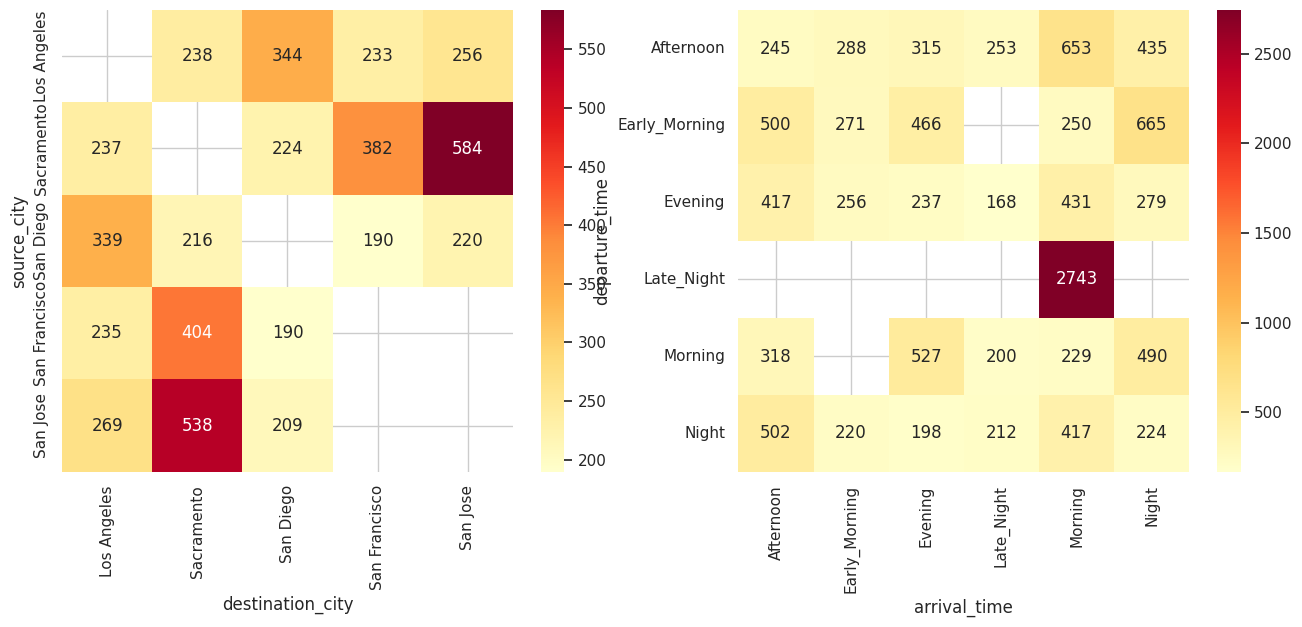

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=train, x="flight_class", y=TARGET, hue="stops", showfliers=False, ax=axes[0])
sns.boxplot(data=train, x="airline", y=TARGET, hue="flight_class", showfliers=False, ax=axes[1])
axes[1].tick_params(axis="x", rotation=30)
sns.scatterplot(data=s, x="duration", y=TARGET, hue="stops", alpha=.4, ax=axes[2])
plt.show()

route = train.pivot_table(index="source_city", columns="destination_city", values=TARGET, aggfunc="mean")
times = train.pivot_table(index="departure_time", columns="arrival_time", values=TARGET, aggfunc="mean")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(route, annot=True, fmt=".0f", cmap="YlOrRd", ax=axes[0])
sns.heatmap(times, annot=True, fmt=".0f", cmap="YlOrRd", ax=axes[1])
plt.show()

            feature          F  p_value  eta_squared
6      flight_class  3978.3573      0.0       0.1804
3             stops  1647.8757      0.0       0.1542
0           airline   186.3072      0.0       0.0583
2    departure_time   186.8696      0.0       0.0492
1       source_city   217.1418      0.0       0.0459
5  destination_city   214.7493      0.0       0.0454
4      arrival_time    34.3064      0.0       0.0094


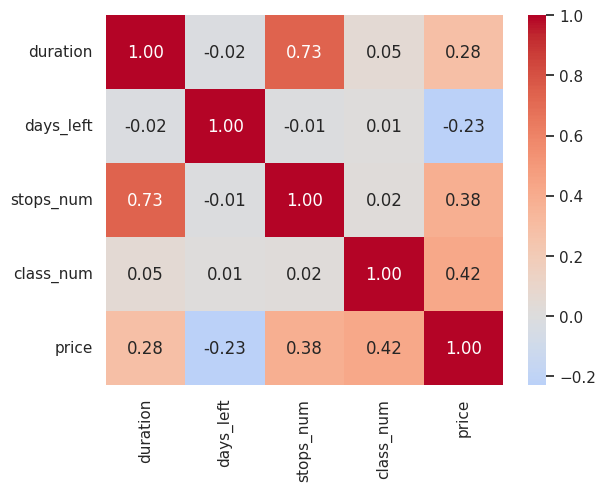

In [12]:
rows = []
for c in CAT_COLS:
    groups = [g[TARGET].values for _, g in train.groupby(c)]
    f, p = stats.f_oneway(*groups)
    grand = train[TARGET].mean()
    ss_b = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    ss_t = ((train[TARGET] - grand) ** 2).sum()
    rows.append((c, f, p, ss_b / ss_t))
assoc = pd.DataFrame(rows, columns=["feature","F","p_value","eta_squared"]).sort_values("eta_squared", ascending=False)
print(assoc.round(4))

tmp = train.copy()
tmp["stops_num"] = tmp["stops"].map({"zero":0, "one":1, "two_or_more":2})
tmp["class_num"] = (tmp["flight_class"] == "Business").astype(int)
sns.heatmap(tmp[["duration","days_left","stops_num","class_num",TARGET]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", center=0); plt.show()

In [13]:
for cls, g in train.groupby("flight_class"):
    q1, q3 = g[TARGET].quantile([.25, .75]); iqr = q3 - q1
    n = ((g[TARGET] < q1 - 1.5*iqr) | (g[TARGET] > q3 + 1.5*iqr)).sum()
    print(f"{cls:9s} n={len(g)} range=[{g[TARGET].min()}, {g[TARGET].max()}] outliers={n} ({n/len(g):.1%})")

dur = train.groupby(["source_city","destination_city","stops"])["duration"].agg(["count","mean","std"]).round(2)
print(dur.sort_values("std", ascending=False).head(10))

Business  n=7365 range=[0, 8996] outliers=658 (8.9%)
Economy   n=10711 range=[0, 1071] outliers=499 (4.7%)
                                            count   mean   std
source_city   destination_city stops                          
Sacramento    San Diego        one            183   8.97  7.83
Los Angeles   Sacramento       one             34  11.34  7.52
San Diego     Sacramento       one            184   8.75  7.42
              San Jose         one            121   7.61  5.32
              San Francisco    one             13   7.37  5.13
San Jose      San Diego        one            116   5.90  4.94
San Francisco San Diego        one             18   6.08  4.73
Los Angeles   San Jose         one             97   7.56  4.56
Sacramento    Los Angeles      one             33  11.01  4.30
San Jose      Los Angeles      two_or_more     16   8.97  3.93
